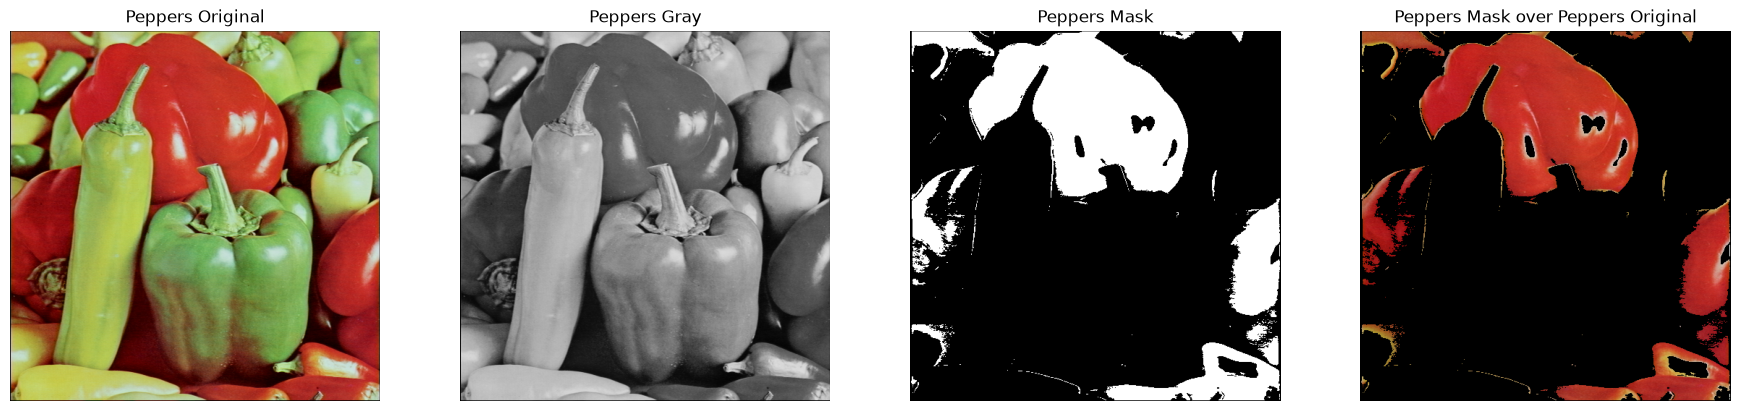

In [17]:
from io import BytesIO
from urllib.request import urlopen
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Localização do arquivo de imagem
image_url = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/peppers3.tif")

# Abertura do arquivo de imagem
with urlopen(image_url) as response:
    original = Image.open(BytesIO(response.read())).convert("RGB")

image_array = np.array(original)

# Conversão de original para níveis de cinza
original_gray = original.convert("L")

# Obtenção dos canais individuais
R = image_array[:, :, 0]
G = image_array[:, :, 1]
B = image_array[:, :, 2]

# Binarização por limiar global para destacar vermelho
# Pixel vermelho tem R alto e G e B mais baixos
threshold = 150
mask = (R > threshold) & (R > G + 20) & (R > B + 20)

# Aplica a máscara na imagem original
result = np.copy(image_array)
result[~mask] = 0


fig, axes = plt.subplots(1, 4, figsize=(18, 4), constrained_layout=True)


# Plots e títulos
axes[0].imshow(original)
axes[0].set_title(f"Peppers Original")
axes[1].imshow(original_gray, cmap= "gray")
axes[1].set_title(f"Peppers Gray",)
axes[2].imshow(mask, cmap="gray")
axes[2].set_title(f"Peppers Mask")
axes[3].imshow(result, cmap="gray")
axes[3].set_title(f"Peppers Mask over Peppers Original")

for ax in axes:
    ax.axis("off")